# Visualizzazione delle sequenze

Per una sequenza del dataset mostra:
1. **prezzo di i0**: proxy di bid, ask e mid ricavati dalle feature di prezzo (anonimizzate, quindi è una ricostruzione approssimativa);
2. **target `t0` e `t1`**, con la banda di clip della metrica `[-2, 2]`;
3. opzionalmente il prezzo di **i1**.

Le zone grigie sono il warm-up (step 0–98); le bande verdi sono le righe `is_scored` (solo nel validation).

> Le colonne `p0…p10` (bid) e `p11…p21` (ask) **non** sono ordinate per livello del book: come proxy di prezzo usiamo la media delle 11 colonne di ciascun lato.

> **Attenzione:** dai primi grafici il "prezzo" ricostruito così è stazionario e limitato, senza trend: le feature `p` sembrano prezzi **relativi** (es. distanze da un riferimento), non il livello assoluto del prezzo.

In [16]:
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / 'datasets').exists() else Path.cwd().parent
DATASETS = ROOT / 'datasets'
TRAIN = DATASETS / 'train.parquet'
VALID = DATASETS / 'valid.parquet'
WARMUP = 99

plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['axes.grid'] = True

## Caricamento
Ogni row group del parquet è una sequenza completa da 20.000 righe, quindi carichiamo solo quella che serve.

In [17]:
_files = {}
_seq_index = {}


def open_dataset(path):
    path = Path(path)
    if path not in _files:
        _files[path] = pq.ParquetFile(path)
    return _files[path]


def seq_index(path):
    """seq_ix -> row group. Legge solo la colonna seq_ix (lento sul train, ~minuti)."""
    path = Path(path)
    if path not in _seq_index:
        ids = open_dataset(path).read(columns=['seq_ix'])['seq_ix'].to_numpy()[::20_000]
        _seq_index[path] = {int(s): g for g, s in enumerate(ids)}
    return _seq_index[path]


def load_sequence(path, group=None, seq_ix=None):
    """Carica una sequenza per indice di row group oppure per seq_ix."""
    if seq_ix is not None:
        group = seq_index(path)[seq_ix]
    df = open_dataset(path).read_row_group(group).to_pandas()
    add_price_proxies(df)
    return df


def add_price_proxies(df):
    for inst in ('i0', 'i1'):
        bid = df[[f'{inst}_p{j}' for j in range(11)]].mean(axis=1)
        ask = df[[f'{inst}_p{j}' for j in range(11, 22)]].mean(axis=1)
        df[f'{inst}_bid'] = bid
        df[f'{inst}_ask'] = ask
        df[f'{inst}_mid'] = (bid + ask) / 2


print(f'valid: {open_dataset(VALID).num_row_groups} sequenze, train: {open_dataset(TRAIN).num_row_groups} sequenze')
# es. per seq_ix: load_sequence(VALID, seq_ix=256678)


valid: 1873 sequenze, train: 10607 sequenze


## Funzione di plot

In [18]:
def _shade_mask(ax, steps, mask, **kw):
    """Disegna bande verticali sui tratti consecutivi in cui mask è True."""
    edges = np.diff(np.r_[0, mask.astype(int), 0])
    for a, b in zip(np.where(edges == 1)[0], np.where(edges == -1)[0]):
        ax.axvspan(steps[a], steps[b - 1] + 1, lw=0, **kw)


TRADE_COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']


def plot_sequence(df, start=0, end=None, show_i1=False, show_trade=False, title=None):
    """show_trade aggiunge due pannelli con le 4 componenti dp (prezzo trade) e dv (volume trade) di i0."""
    d = df.iloc[start:end]
    steps = d['step_in_seq'].to_numpy()
    panels = ['price', 'target'] + (['dp', 'dv'] if show_trade else []) + (['i1'] if show_i1 else [])
    ratios = {'price': 2, 'target': 1.4, 'dp': 1.2, 'dv': 1, 'i1': 1}
    fig, axes = plt.subplots(len(panels), 1, sharex=True,
                             gridspec_kw={'height_ratios': [ratios[p] for p in panels]},
                             figsize=(16, 3.2 * len(panels) + 1))
    ax_of = dict(zip(panels, axes))

    ax = ax_of['price']
    ax.plot(steps, d['i0_bid'], lw=0.8, color='tab:blue', label='i0 bid (media p0–p10)')
    ax.plot(steps, d['i0_ask'], lw=0.8, color='tab:red', label='i0 ask (media p11–p21)')
    ax.plot(steps, d['i0_mid'], lw=1.0, color='black', label='i0 mid')
    ax.set_ylabel('prezzo (normalizzato)')
    ax.legend(loc='upper left', fontsize=9)

    ax = ax_of['target']
    ax.plot(steps, d['t0'], lw=0.9, color='tab:green', label='t0')
    ax.plot(steps, d['t1'], lw=0.9, color='tab:purple', label='t1')
    ax.axhline(0, color='grey', lw=0.6)
    for y in (-2, 2):
        ax.axhline(y, color='grey', lw=0.6, ls='--')
    ax.set_ylabel('target')
    ax.legend(loc='upper left', fontsize=9)

    if show_trade:
        for group, label in (('dp', 'prezzo trade'), ('dv', 'volume trade')):
            ax = ax_of[group]
            for k, color in enumerate(TRADE_COLORS):
                ax.plot(steps, d[f'i0_{group}{k}'], lw=0.7, color=color, alpha=0.8, label=f'i0_{group}{k}')
            ax.set_ylabel(label)
            ax.legend(loc='upper left', fontsize=9, ncol=4)

    if show_i1:
        ax = ax_of['i1']
        ax.plot(steps, d['i1_mid'], lw=0.8, color='tab:brown', label='i1 mid')
        ax.set_ylabel('prezzo i1')
        ax.legend(loc='upper left', fontsize=9)

    for ax in axes:
        _shade_mask(ax, steps, steps < WARMUP, color='grey', alpha=0.2)
        if 'is_scored' in d:
            _shade_mask(ax, steps, d['is_scored'].to_numpy(), color='tab:green', alpha=0.12)
    axes[-1].set_xlabel('step_in_seq')

    seq = int(d['seq_ix'].iloc[0])
    info = f'seq_ix={seq}  step {steps[0]}–{steps[-1]}'
    if 'is_scored' in d:
        info += f'  scored={int(d["is_scored"].sum())}'
    fig.suptitle(title or info)
    fig.tight_layout()
    plt.show()


## Una sequenza intera o con zoom

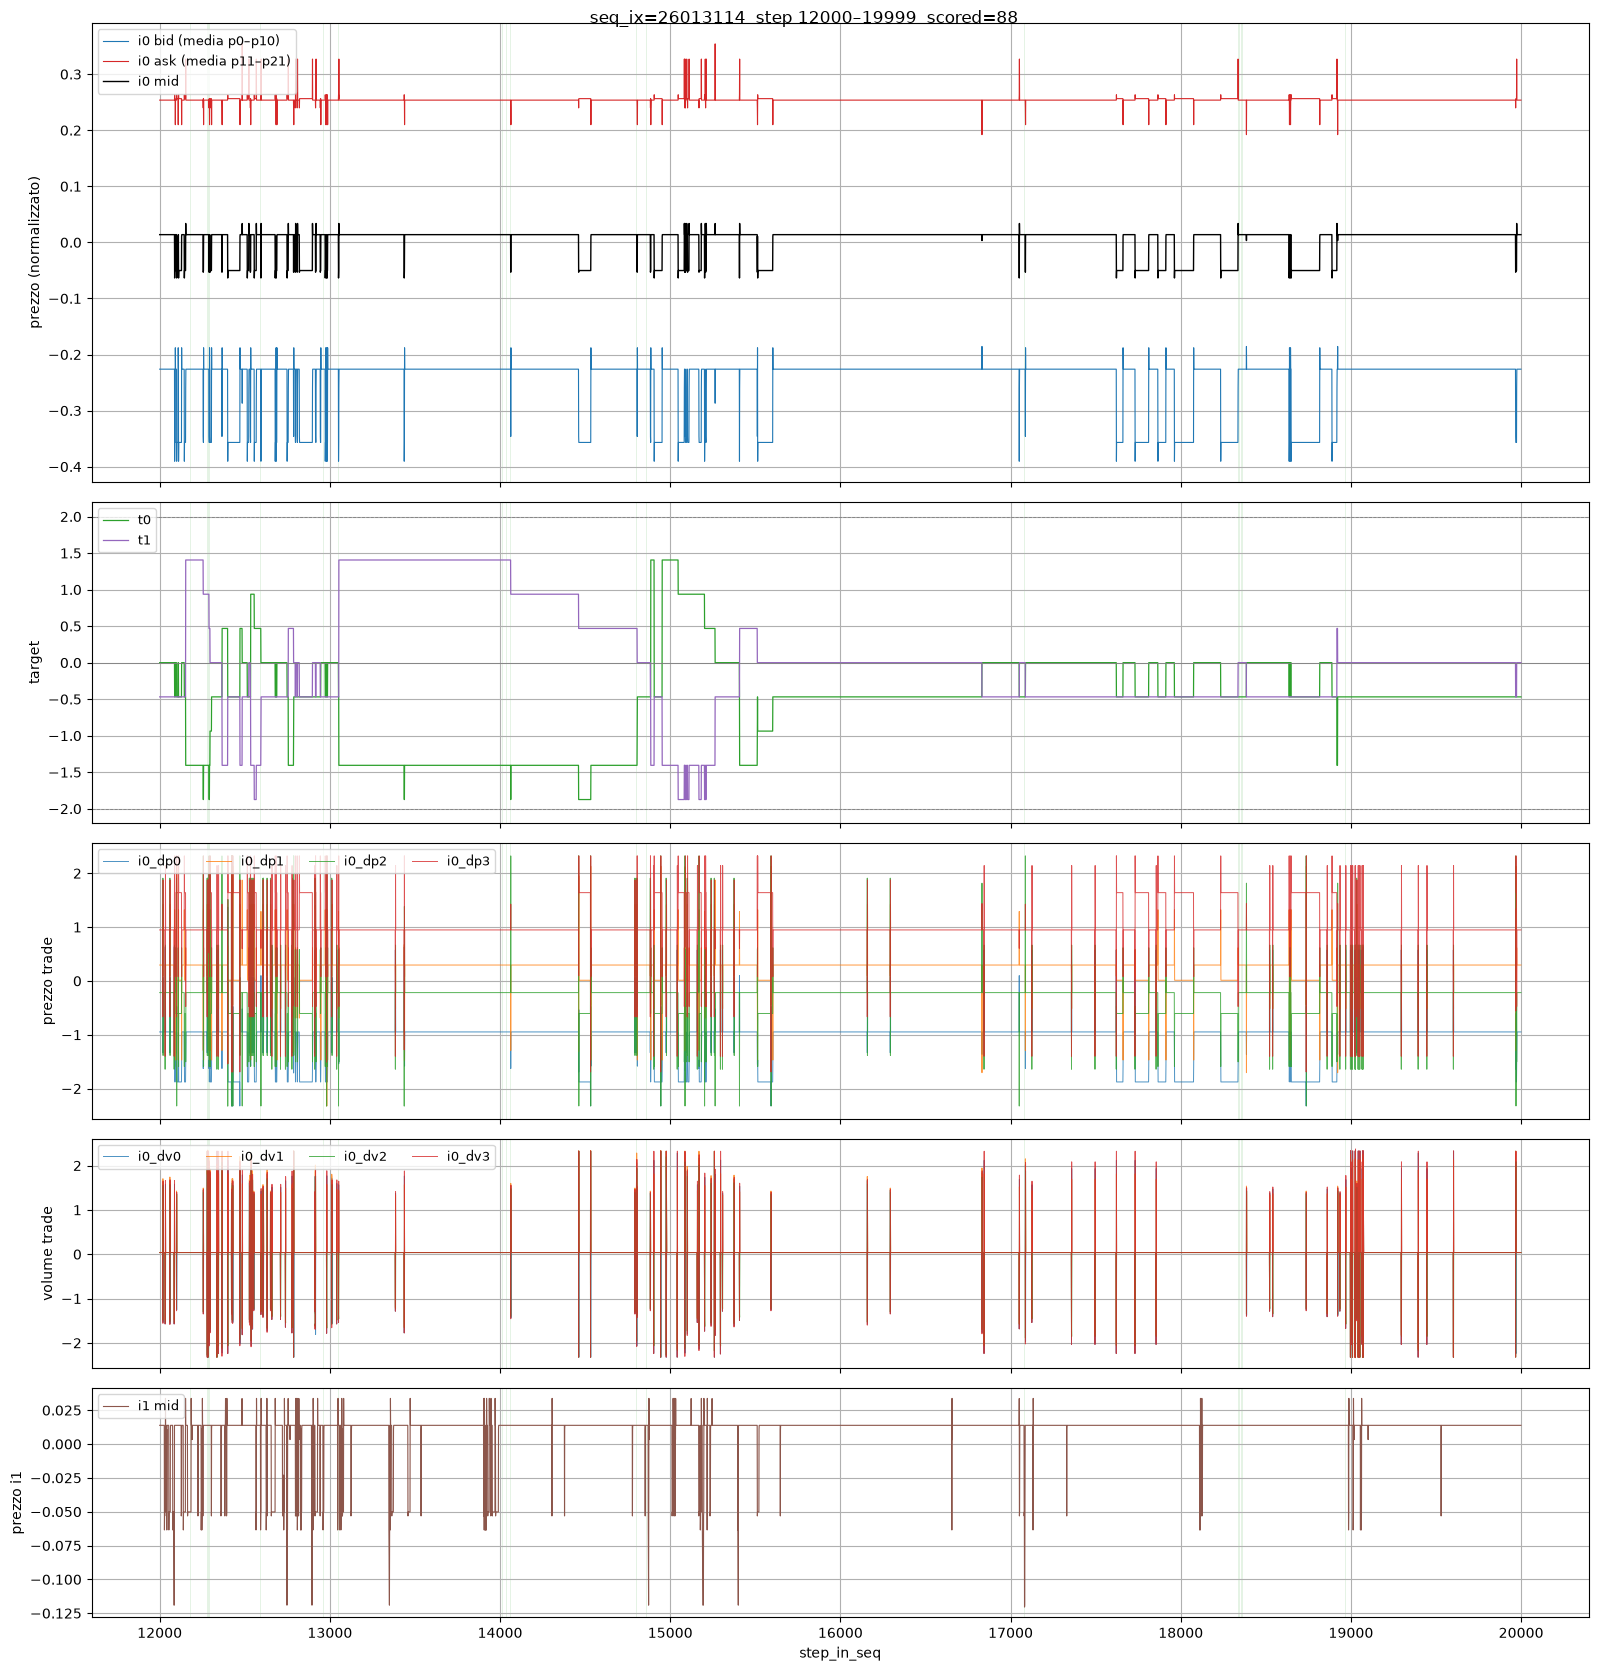

In [29]:
df = load_sequence(VALID, group=20)
plot_sequence(df, start=12000, end=20000, show_trade=True, show_i1=True)

## Order book: le singole colonne

Tutte le 11 colonne di ciascun lato, senza medie: prezzi bid (`p0–p10`), prezzi ask (`p11–p21`) e, se richiesto, i volumi (`v0–v10`, `v11–v21`).
Il colore indica l'indice della colonna (scuro = indice basso). Ricorda: l'indice **non** è il livello del book.

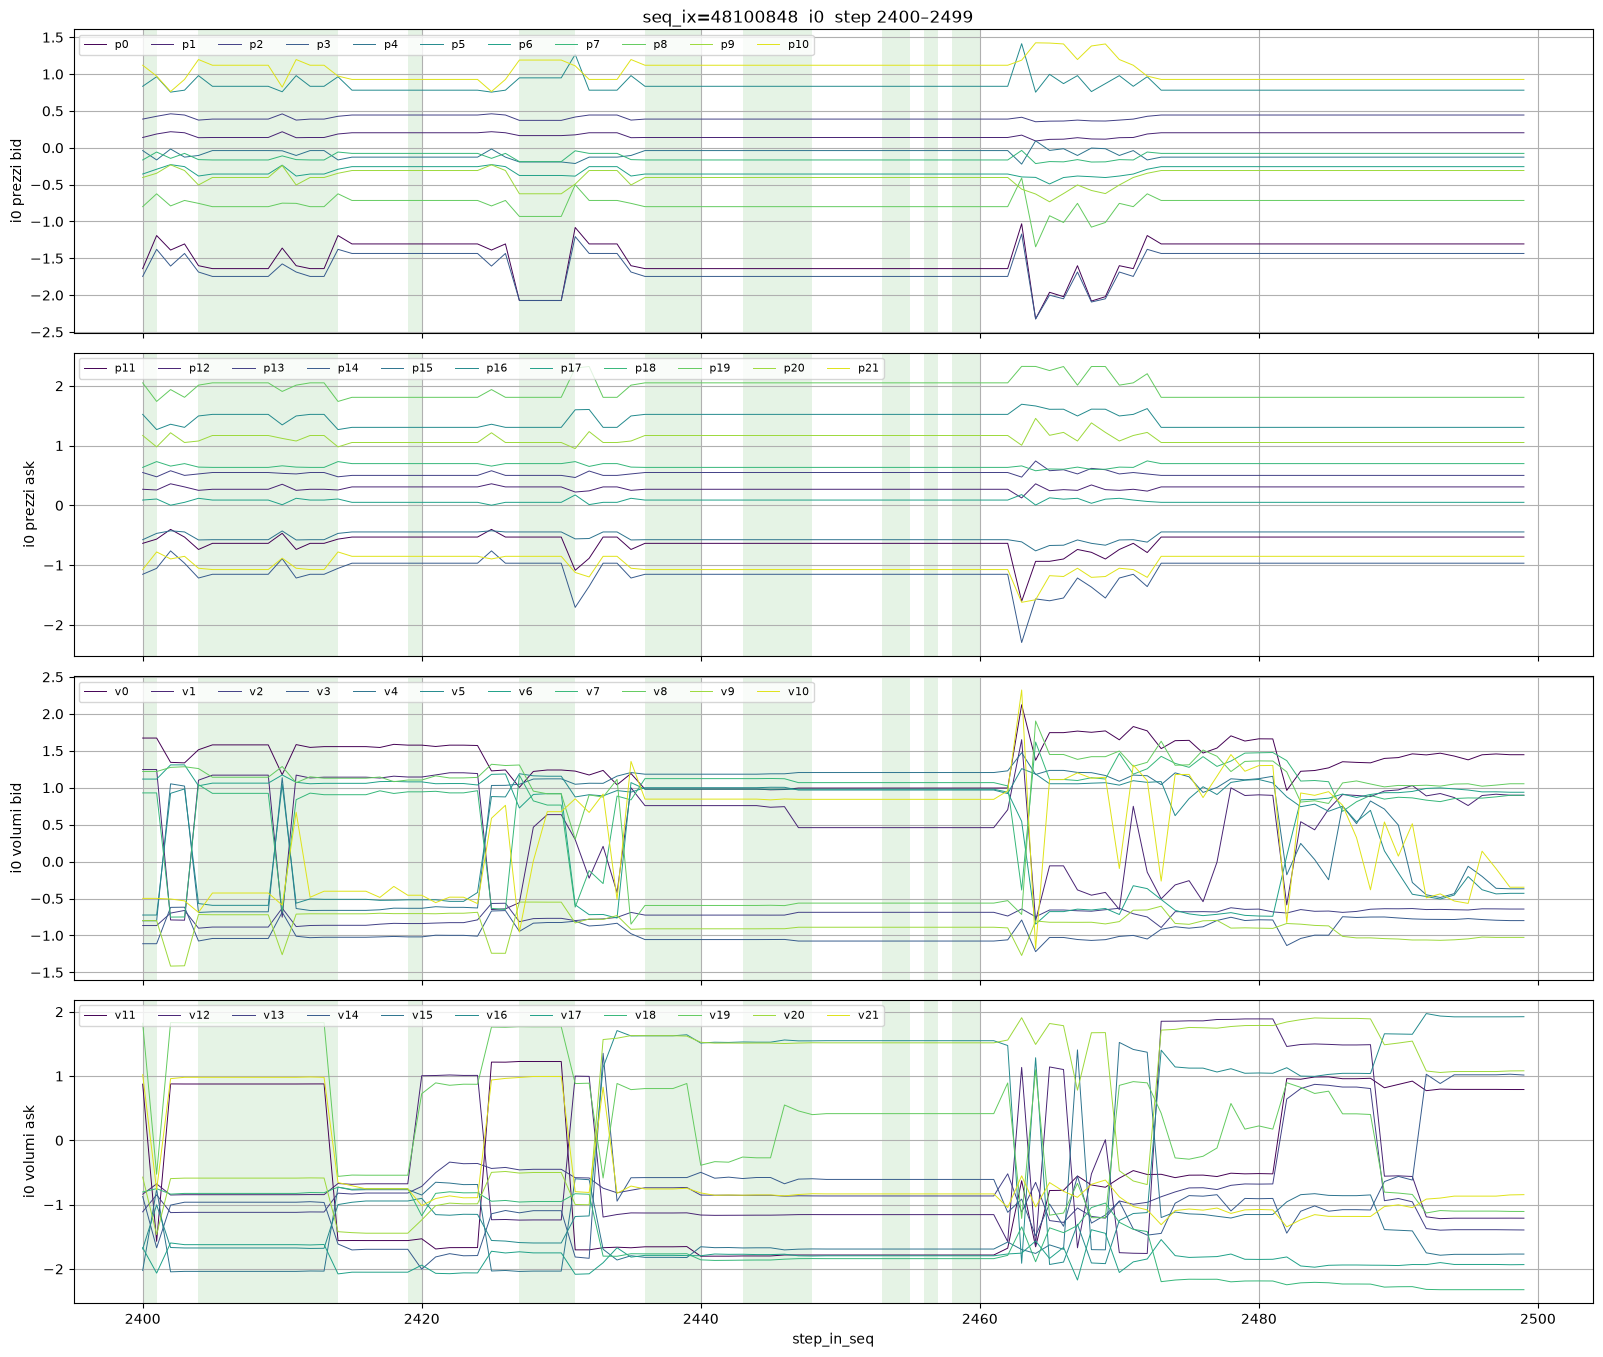

In [25]:
def plot_book(df, start=0, end=None, inst='i0', show_volume=True):
    d = df.iloc[start:end]
    steps = d['step_in_seq'].to_numpy()
    groups = [('prezzi bid', 'p', range(0, 11)), ('prezzi ask', 'p', range(11, 22))]
    if show_volume:
        groups += [('volumi bid', 'v', range(0, 11)), ('volumi ask', 'v', range(11, 22))]
    fig, axes = plt.subplots(len(groups), 1, sharex=True, figsize=(16, 3.2 * len(groups) + 1))
    colors = plt.cm.viridis(np.linspace(0, 0.95, 11))

    for ax, (label, kind, idx) in zip(axes, groups):
        for color, j in zip(colors, idx):
            ax.plot(steps, d[f'{inst}_{kind}{j}'], lw=0.7, color=color, label=f'{kind}{j}')
        ax.set_ylabel(f'{inst} {label}')
        ax.legend(loc='upper left', fontsize=8, ncol=11)
        _shade_mask(ax, steps, steps < WARMUP, color='grey', alpha=0.2)
        if 'is_scored' in d:
            _shade_mask(ax, steps, d['is_scored'].to_numpy(), color='tab:green', alpha=0.12)
    axes[-1].set_xlabel('step_in_seq')
    fig.suptitle(f'seq_ix={int(d["seq_ix"].iloc[0])}  {inst}  step {steps[0]}–{steps[-1]}')
    fig.tight_layout()
    plt.show()


plot_book(df, start=2400, end=2500)